In [2]:
# Task 1

import pandas as pd

zomato = pd.read_csv("S7_zomato_ratings.csv")

ratings = zomato["user_rating"]


Q1 = ratings.quantile(0.25)
Q3 = ratings.quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = zomato[
    (ratings < lower_limit) | (ratings > upper_limit)
]

print("Indices of detected outliers:")
print(outliers.index)

print("\nOutlier rows:")
print(outliers)

Indices of detected outliers:
RangeIndex(start=6, stop=7, step=1)

Outlier rows:
  restaurant  user_rating
6     Honest          2.0


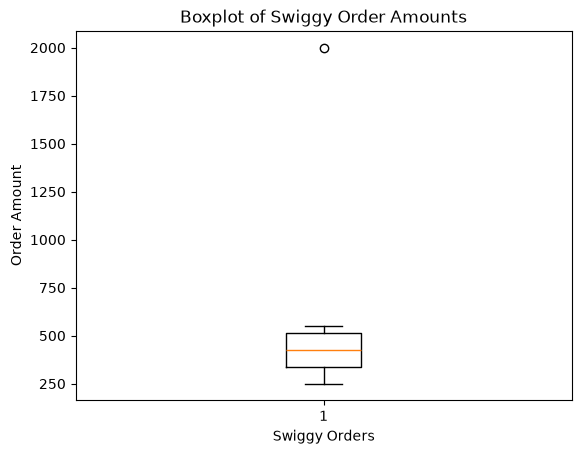

In [3]:
# Task2

import pandas as pd
import matplotlib.pyplot as plt

swiggy = pd.DataFrame({
    "order_id": [101, 102, 103, 104, 105, 106, 107, 108],
    "order_amount": [250, 400, 350, 500, 450, 300, 550, 2000]
})

plt.boxplot(swiggy["order_amount"])

plt.xlabel("Swiggy Orders")
plt.ylabel("Order Amount")

plt.title("Boxplot of Swiggy Order Amounts")

plt.show()

In [4]:
# Task3

import pandas as pd

paytm = pd.DataFrame({
    "transaction_amount": [
        100, 250, 300, 450, 500,
        600, 750, 900, 1200, 5000
    ]
})

print("Before Winsorization:")
print(paytm["transaction_amount"])

# Calculate 5th and 95th percentiles
lower_limit = paytm["transaction_amount"].quantile(0.05)
upper_limit = paytm["transaction_amount"].quantile(0.95)

# Apply Winsorization
paytm["transaction_amount"] = paytm["transaction_amount"].clip(
    lower=lower_limit,
    upper=upper_limit
)

print("\nAfter Winsorization:")
print(paytm["transaction_amount"])

# Display updated statistics
print("\nUpdated Statistics:")
print(paytm["transaction_amount"].describe())

Before Winsorization:
0     100
1     250
2     300
3     450
4     500
5     600
6     750
7     900
8    1200
9    5000
Name: transaction_amount, dtype: int64

After Winsorization:
0     167.5
1     250.0
2     300.0
3     450.0
4     500.0
5     600.0
6     750.0
7     900.0
8    1200.0
9    3290.0
Name: transaction_amount, dtype: float64

Updated Statistics:
count      10.000000
mean      840.750000
std       916.578822
min       167.500000
25%       337.500000
50%       550.000000
75%       862.500000
max      3290.000000
Name: transaction_amount, dtype: float64


In [5]:
# Task4 

import pandas as pd

flipkart = pd.DataFrame({
    "product": ["Laptop", "Phone", "Headphones", "Keyboard"],
    "price": ["₹1,299", "₹25,999", "₹1,499", "₹799"]
})

print("Before conversion:")
print(flipkart)
print(flipkart["price"].dtype)

flipkart["price"] = flipkart["price"].str.replace("₹", "", regex=False)
flipkart["price"] = flipkart["price"].str.replace(",", "", regex=False)

flipkart["price"] = flipkart["price"].astype(float)

print("\nAfter conversion:")
print(flipkart)
print(flipkart["price"].dtype)

Before conversion:
      product    price
0      Laptop   ₹1,299
1       Phone  ₹25,999
2  Headphones   ₹1,499
3    Keyboard     ₹799
str

After conversion:
      product    price
0      Laptop   1299.0
1       Phone  25999.0
2  Headphones   1499.0
3    Keyboard    799.0
float64


In [6]:
# Task5

import pandas as pd

spotify = pd.DataFrame({
    "user": ["A", "B", "C", "D", "E", "F", "G"],
    "is_premium": [True, "True", 1, "yes", "no", 0, "False"]
})

print("Before conversion:")
print(spotify)

spotify["is_premium"] = spotify["is_premium"].apply(
    lambda x: True if x is True or x == "True" or x == 1 or x == "yes" else False
)

print("\nAfter conversion:")
print(spotify)

print("\nData type:")
print(spotify["is_premium"].dtype)

Before conversion:
  user is_premium
0    A       True
1    B       True
2    C          1
3    D        yes
4    E         no
5    F          0
6    G      False

After conversion:
  user  is_premium
0    A        True
1    B        True
2    C        True
3    D        True
4    E       False
5    F       False
6    G       False

Data type:
bool
